In [1]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


In [2]:
df = pd.read_csv("../dataset/heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())


Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical 

In [3]:
X = df.drop("Heart Disease", axis=1)
y = df["Heart Disease"]


In [4]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("\nNumerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))



Numerical Features:
['Age', 'Cholesterol', 'Blood Pressure', 'Heart Rate', 'Exercise Hours', 'Stress Level', 'Blood Sugar']

Categorical Features:
['Gender', 'Smoking', 'Alcohol Intake', 'Family History', 'Diabetes', 'Obesity', 'Exercise Induced Angina', 'Chest Pain Type']


E:\temp\ipykernel_11772\2468435836.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns


In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [7]:
kernels = ["linear", "poly", "rbf", "sigmoid"]

results = []


In [8]:
for kernel in kernels:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("svm", SVC(kernel=kernel, random_state=42))
        ]
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append([
        kernel,
        accuracy,
        precision,
        recall,
        f1
    ])

    print("\n======================================")
    print("SVM Kernel:", kernel)
    print("======================================")

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))



SVM Kernel: linear
Accuracy : 0.875
Precision: 0.8732394366197183
Recall   : 0.7948717948717948
F1 Score : 0.8322147651006712

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90       122
           1       0.87      0.79      0.83        78

    accuracy                           0.88       200
   macro avg       0.87      0.86      0.87       200
weighted avg       0.87      0.88      0.87       200


SVM Kernel: poly
Accuracy : 0.925
Precision: 0.9315068493150684
Recall   : 0.8717948717948718
F1 Score : 0.9006622516556292

Classification Report:


              precision    recall  f1-score   support

           0       0.92      0.96      0.94       122
           1       0.93      0.87      0.90        78

    accuracy                           0.93       200
   macro avg       0.93      0.92      0.92       200
weighted avg       0.93      0.93      0.92       200


SVM Kernel: rbf
Accuracy : 0.905
Precision: 0.8933333333333333
Recall   : 0.8589743589743589
F1 Score : 0.8758169934640523

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.93      0.92       122
           1       0.89      0.86      0.88        78

    accuracy                           0.91       200
   macro avg       0.90      0.90      0.90       200
weighted avg       0.90      0.91      0.90       200


SVM Kernel: sigmoid
Accuracy : 0.825
Precision: 0.8028169014084507
Recall   : 0.7307692307692307
F1 Score : 0.7651006711409396

Classification Report:
              precision    recall  f1-score   

In [9]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Kernel",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\n\nKernel Comparison:")
print(results_df)




Kernel Comparison:
    Kernel  Accuracy  Precision    Recall  F1 Score
0   linear     0.875   0.873239  0.794872  0.832215
1     poly     0.925   0.931507  0.871795  0.900662
2      rbf     0.905   0.893333  0.858974  0.875817
3  sigmoid     0.825   0.802817  0.730769  0.765101


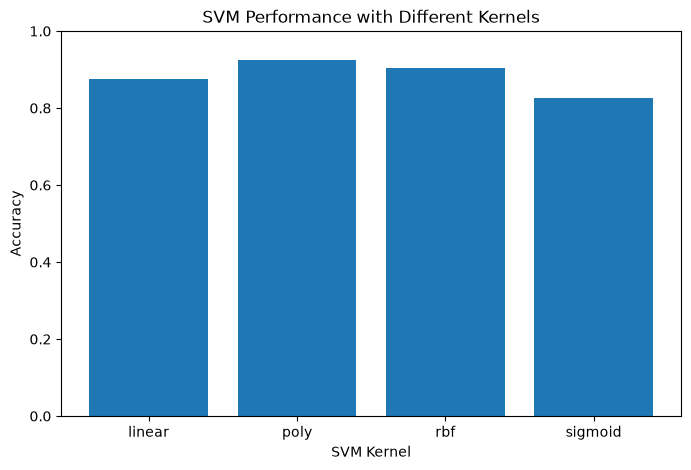


Result:
SVM classification was successfully performed
using Linear, Polynomial, RBF and Sigmoid kernels.


In [10]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Kernel"],
    results_df["Accuracy"]
)

plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy")
plt.title("SVM Performance with Different Kernels")
plt.ylim(0, 1)

plt.show()

# ------------------------------------------------------------
# Result
# ------------------------------------------------------------

print("\nResult:")
print("SVM classification was successfully performed")
print("using Linear, Polynomial, RBF and Sigmoid kernels.")
